Tugas Praktikum - Wisconsin Breast Cancer (WBC).

1. Pisahkan variabel yang dapat dipakai (30 fitur numerik) dari yang tidak
   (id = identitas unik, Unnamed: 32 = kolom kosong).
2. Encoding kolom diagnosis: M=1 (malignant), B=0 (benign).
3. Standarisasi semua kolom numerik.
4. Stratified split 80:20.
Output: output/*.png, output/wbc_train.csv, output/wbc_test.csv

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("wbc_preprocessing.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js03-ektraksi-fitur\tugas


In [2]:
from pathlib import Path

import pandas as pd
import matplotlib

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

HERE = Path(__file__).resolve().parent
DATA = HERE.parent / "data"
OUT = HERE / "output"
OUT.mkdir(exist_ok=True)

df = pd.read_csv(DATA / "wbc.csv")
print(f"Shape awal: {df.shape}")
print(f"Kolom: {df.columns.tolist()[:3]} ... ({df.shape[1]} kolom)")

Shape awal: (569, 33)
Kolom: ['id', 'diagnosis', 'radius_mean'] ... (33 kolom)


In [3]:
# --- 1. pemisahan variabel ---
drop_cols = [c for c in ["id", "Unnamed: 32"] if c in df.columns]
print(f"\nKolom dibuang (bukan fitur): {drop_cols}")
for c in drop_cols:
    non_null = df[c].notna().sum()
    print(f"  {c}: non-null={non_null}, unik={df[c].nunique()}")

df = df.drop(columns=drop_cols)
num_cols = [c for c in df.columns if c != "diagnosis"]
print(f"Jumlah fitur numerik dipakai: {len(num_cols)}")


Kolom dibuang (bukan fitur): ['id', 'Unnamed: 32']
  id: non-null=569, unik=569
  Unnamed: 32: non-null=0, unik=0
Jumlah fitur numerik dipakai: 30


In [4]:
# --- 2. encoding diagnosis ---
print(f"\nSebelum encoding: {df['diagnosis'].value_counts().to_dict()}")
df["diagnosis"] = df["diagnosis"].map({"M": 1, "B": 0})
assert df["diagnosis"].notna().all(), "ada label tak dikenal"
print(f"Setelah encoding: {df['diagnosis'].value_counts().sort_index().to_dict()} "
      f"| {df['diagnosis'].dtype}")


Sebelum encoding: {'B': 357, 'M': 212}
Setelah encoding: {0: 357, 1: 212} | int64


In [5]:
# --- 3. standarisasi seluruh kolom numerik ---
print("\nSebelum standarisasi (3 baris pertama):")
print(df[num_cols].head(3).round(3).to_string())
scaler = StandardScaler()
df[num_cols] = scaler.fit_transform(df[num_cols])
print("\nSesudah standarisasi (3 baris pertama):")
print(df[num_cols].head(3).round(4).to_string())
print(f"\nCek: mean semua fitur ~0 -> max |mean| = {df[num_cols].mean().abs().max():.2e}")
print(f"     std semua fitur ~1 -> max |std-1| = {(df[num_cols].std(ddof=0) - 1).abs().max():.2e}")


Sebelum standarisasi (3 baris pertama):
   radius_mean  texture_mean  perimeter_mean  area_mean  smoothness_mean  compactness_mean  concavity_mean  concave points_mean  symmetry_mean  fractal_dimension_mean  radius_se  texture_se  perimeter_se  area_se  smoothness_se  compactness_se  concavity_se  concave points_se  symmetry_se  fractal_dimension_se  radius_worst  texture_worst  perimeter_worst  area_worst  smoothness_worst  compactness_worst  concavity_worst  concave points_worst  symmetry_worst  fractal_dimension_worst
0        17.99         10.38           122.8     1001.0            0.118             0.278           0.300                0.147          0.242                   0.079      1.095       0.905         8.589   153.40          0.006           0.049         0.054              0.016        0.030                 0.006         25.38          17.33            184.6      2019.0             0.162              0.666            0.712                 0.265           0.460           

In [6]:
# --- 4. stratified split 80:20 ---
X = df[num_cols]
y = df["diagnosis"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\n=== Stratified split 80:20 ===")
for nama, yy in (("asli", y), ("train", y_tr), ("test", y_te)):
    vc = yy.value_counts().sort_index()
    print(f"{nama:5s} n={len(yy):3d} | B(0)={vc[0]:3d} M(1)={vc[1]:3d} "
          f"| proporsi M={yy.mean():.4f}")
print(f"X_train {X_tr.shape}, X_test {X_te.shape}")
print(f"Total = {len(X_tr) + len(X_te)} (harus 569)")

pd.concat([y_tr.rename("diagnosis"), X_tr], axis=1).to_csv(
    OUT / "wbc_train.csv", index=False)
pd.concat([y_te.rename("diagnosis"), X_te], axis=1).to_csv(
    OUT / "wbc_test.csv", index=False)
print("Dataset split disimpan -> output/wbc_train.csv, output/wbc_test.csv")


=== Stratified split 80:20 ===
asli  n=569 | B(0)=357 M(1)=212 | proporsi M=0.3726
train n=455 | B(0)=285 M(1)=170 | proporsi M=0.3736
test  n=114 | B(0)= 72 M(1)= 42 | proporsi M=0.3684
X_train (455, 30), X_test (114, 30)
Total = 569 (harus 569)
Dataset split disimpan -> output/wbc_train.csv, output/wbc_test.csv


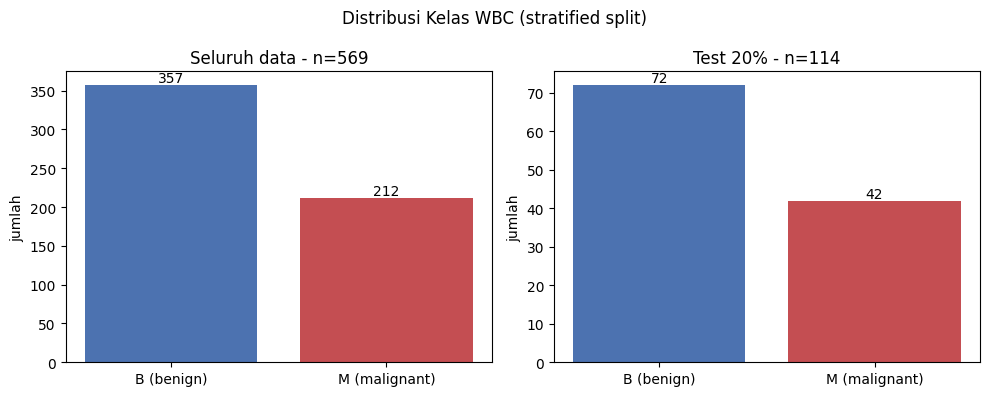

In [7]:
# visualisasi
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, yy, t in ((axes[0], y, "Seluruh data"), (axes[1], y_te, "Test 20%")):
    counts = yy.value_counts().sort_index()
    ax.bar(["B (benign)", "M (malignant)"], counts.values,
           color=["#4c72b0", "#c44e52"])
    ax.set_title(f"{t} - n={len(yy)}")
    ax.set_ylabel("jumlah")
    for i, v in enumerate(counts.values):
        ax.text(i, v, str(v), ha="center", va="bottom")
fig.suptitle("Distribusi Kelas WBC (stratified split)")
fig.tight_layout()
fig.savefig(OUT / "wbc_distribusi_kelas.png", dpi=120)


Top-5 fitur |korelasi| terhadap diagnosis:
concave points_worst    0.7936
perimeter_worst         0.7829
concave points_mean     0.7766
radius_worst            0.7765
perimeter_mean          0.7426


grafik -> output/wbc_distribusi_kelas.png, output/wbc_korelasi_fitur.png

Selesai tugas praktikum.


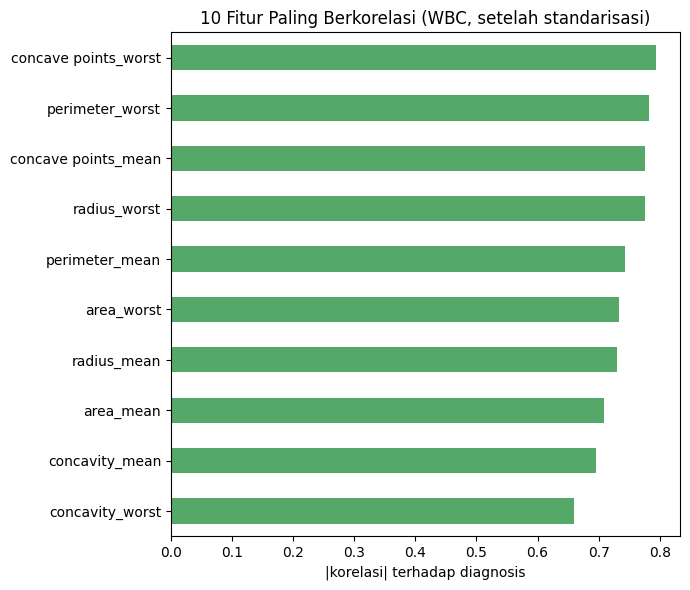

In [8]:
# korelasi fitur teratas terhadap label
corr = df.corr()["diagnosis"].drop("diagnosis").abs().sort_values(ascending=False)
print("\nTop-5 fitur |korelasi| terhadap diagnosis:")
print(corr.head(5).round(4).to_string())
fig, ax = plt.subplots(figsize=(7, 6))
corr.head(10)[::-1].plot(kind="barh", ax=ax, color="#55a868")
ax.set_xlabel("|korelasi| terhadap diagnosis")
ax.set_title("10 Fitur Paling Berkorelasi (WBC, setelah standarisasi)")
fig.tight_layout()
fig.savefig(OUT / "wbc_korelasi_fitur.png", dpi=120)
print("grafik -> output/wbc_distribusi_kelas.png, output/wbc_korelasi_fitur.png")

print("\nSelesai tugas praktikum.")